# 2.0 — Procesamiento: temperatura SMN/CONAGUA

**Capa 2 del protocolo (clima).** Convierte los resúmenes mensuales por
estación de `01_ingesta/1.0-conagua-temperatura.ipynb` (TMed, TMax, TMin)
en una sola serie mensual para Hermosillo, la que usa el panel integrado
(`03_eda/3.0-integracion-espacial.ipynb`).

## Entradas

| Ruta | Contenido |
|------|-----------|
| `data/raw/temperatura_AAAA/*.csv` | Temperatura media mensual por estación (`Tmed`) |
| `data/raw/temperatura_max_AAAA/*.csv` | Temperatura máxima mensual por estación (`Tmax`) |
| `data/raw/temperatura_min_AAAA/*.csv` | Temperatura mínima mensual por estación (`Tmin`) |

## Salidas

- `data/interim/clima/temperatura_smn_hermosillo_mensual.csv` (opcional,
  para revisión): `fecha_mes`, `temp_media_c`, `temp_max_media_c`,
  `temp_min_media_c`.
- Decisiones de limpieza registradas al final del notebook.

## Funciones del paquete

`panel.load_smn_temperature()`, `load_smn_temperature_max()`,
`load_smn_temperature_min()` y `panel.climate_hermosillo()` (filtra las
estaciones de `config.CLIMATE_STATION_IDS`, promedia y marca los meses
corruptos).

## Checklist

- [x] Cobertura: meses con dato por estación de Hermosillo.
- [x] Valores centinela del SMN (`-99.9`, `-999`) y rangos físicos (`Tmin ≤ Tmed ≤ Tmax`).
- [x] Meses corruptos en la fuente (mismo valor en TMed/TMax/TMin) → NaN.
- [x] Promedio entre estaciones y número de estaciones que aporta cada mes.
- [x] Faltantes en la serie mensual final (se tratan en `03_eda/3.1-datos-faltantes.ipynb`).


### ¿Qué problema resuelve este notebook?

Los archivos del SMN traen la temperatura de **más de 1,900 estaciones de todo México**, mes por mes. Pero el proyecto necesita **una sola serie de temperatura para Hermosillo** (un valor por mes), y que sea **confiable**.

Este notebook es una **revisión de calidad**: antes de usar los datos, comprobamos que no tengan errores.

### El recorrido, paso a paso

```
Configuración  →  Carga  →  Cobertura  →  Centinelas y rangos  →  Meses corruptos  →  Serie de Hermosillo  →  Guardar
(herramientas)   (leer     (¿hay datos    (¿hay valores          (¿hay meses         (promedio mensual     (opcional)
                  datos)    suficientes?)  imposibles?)           dañados?)           + gráfica)
```


### Mini glosario

| Término | Qué significa |
|---------|---------------|
| **Estación** | Un punto de medición del clima. Se identifica con su `clave` (por ejemplo `HM2SO`). |
| **Estación-mes** | Una fila de la tabla: la lectura de **una estación en un mes**. |
| **`NaN`** | Un valor vacío (sin dato). |
| **Valor centinela** | Un número como `-99.9` que la fuente usa para decir "no hay dato". Si se lee como temperatura real, arruina los promedios. |
| **`fecha_mes`** | El mes de la lectura (por ejemplo `2015-01`). |
| **Filtrar** | Quedarse solo con las filas que cumplen una condición. |
| **`groupby` (agrupar)** | Juntar filas que comparten algo (por ejemplo, el mismo mes) para contarlas o promediarlas. |
| **`merge` (unir)** | Pegar dos tablas usando columnas en común, como buscar con `BUSCARV` en Excel. |

## Configuración e imports

En esta parte se cargan las herramientas (librerías) y las funciones del proyecto que se usarán en el resto del notebook.

**Qué trae cada parte:**
- `CLIMATE_STATION_IDS` (de `config.py`): las claves de las estaciones de Hermosillo.
- Las funciones de `panel.py`: leen los CSV del SMN y calculan la serie de Hermosillo.

**Cómo leer el resultado:** debe imprimir `Estaciones de Hermosillo: ['HM2SO', 'HMNSO', 'MMHO']`.

**Si falla:** el mensaje `No module named 'sonora_health_climate_eda'` significa que el kernel elegido no es el del proyecto, o falta instalarlo con `pip install -e .`.

In [9]:
from pathlib import Path  # Path: herramienta para manejar rutas de carpetas y archivos
import sys  # sys: permite cambiar dónde busca módulos Python

# Este notebook vive en notebooks/02_procesamiento/. Con .parent.parent subimos
# dos carpetas hasta llegar a la raíz del proyecto.
ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
# Si la raíz del proyecto no está en la lista de búsqueda de Python, la agrega.
# Así se puede importar el paquete `sonora_health_climate_eda`.
if str(ROOT_DIR) not in sys.path: # Si la raíz del proyecto no está en la lista de búsqueda de Python, la agrega.
    sys.path.append(str(ROOT_DIR))

import numpy as np  # numpy: cálculos numéricos (aquí lo usamos para comparar decimales)
import pandas as pd  # pandas: trabajar con tablas (DataFrames)
import matplotlib.pyplot as plt  # matplotlib: hacer gráficas

# De config.py: las claves de las estaciones de Hermosillo y la ruta de data/interim
from sonora_health_climate_eda.config import CLIMATE_STATION_IDS, INTERIM_DATA_DIR

# De panel.py: funciones que leen los CSV del SMN y calculan la serie de Hermosillo
from sonora_health_climate_eda.panel import (
    climate_hermosillo,  # promedia las estaciones de Hermosillo por mes
    load_smn_temperature,  # lee la temperatura MEDIA de todas las estaciones
    load_smn_temperature_max,  # lee la temperatura MÁXIMA de todas las estaciones
    load_smn_temperature_min,  # lee la temperatura MÍNIMA de todas las estaciones
)

# Carpeta donde se guardaría el resultado: data/interim/clima
OUT_DIR = INTERIM_DATA_DIR / "clima"
# Imprime las claves de las estaciones de Hermosillo para confirmar que se cargaron
print("Estaciones de Hermosillo:", CLIMATE_STATION_IDS)

Estaciones de Hermosillo: ['HM2SO', 'HMNSO', 'MMHO']


## Carga por estación

En esta parte se leen todos los CSV mensuales del SMN (los que están en `data/raw/`) y se juntan en tres tablas: temperatura media (`tmed`), máxima (`tmax`) y mínima (`tmin`). Se busca tener los datos en tablas con las que se pueda trabajar. Cada fila es **una estación en un mes**, de todo México. Para cada tabla se imprime cuántas filas tiene, cuántas estaciones distintas hay y de qué mes a qué mes van los datos. Debe verse `2015-01 a 2020-12`.

**Resultado de nuestra corrida:** cada tabla tiene unas 77,000 filas y 1,939 estaciones, con datos de 2015-01 a 2020-12. Son 72 meses con unas 1,070 estaciones por mes. Las tres tablas tienen un número casi igual de filas, y la pequeña diferencia es normal: no todas las estaciones reportan las tres temperaturas cada mes.

**Si falla:** el error `No objects to concatenate` significa que faltan las carpetas de temperatura máxima o mínima en `data/raw/` (se descargan con `download-temperature-extremes-data`).

In [ ]:
# Carga las tres tablas con las funciones de panel.py. Cada una lee TODOS los
# CSV mensuales de su carpeta en data/raw/ y los junta en una sola tabla.
tmed = load_smn_temperature()  # temperatura media   (data/raw/temperatura_AAAA)
tmax = load_smn_temperature_max()  # temperatura máxima  (data/raw/temperatura_max_AAAA)
tmin = load_smn_temperature_min()  # temperatura mínima  (data/raw/temperatura_min_AAAA)

# Recorre las tres tablas e imprime un resumen de cada una.
# .items() entrega pares (nombre, tabla): ("TMed", tmed), ("TMax", tmax), ("TMin", tmin)
for nombre, df in {"TMed": tmed, "TMax": tmax, "TMin": tmin}.items(): # el diccionario sirve para recorrer las tres tablas de manera ordenada y con nombre
    print(
        # len(df) = número de filas; ":," agrega comas a los miles (77,027)
        f"{nombre}: {len(df):,} filas estación-mes, "
        # nunique() = cuántas claves de estación distintas hay
        f"{df['clave'].nunique()} estaciones, "
        # min() y max() de fecha_mes = primer y último mes de la tabla
        f"{df['fecha_mes'].min()} a {df['fecha_mes'].max()}"
    )

2026-11-13 16:58:14.091 | INFO     | sonora_health_climate_eda.panel:_load_smn_temperature_series:81 - SMN temp_media_c: 77027 filas estación-mes.
2026-11-13 16:58:15.172 | INFO     | sonora_health_climate_eda.panel:_load_smn_temperature_series:81 - SMN temp_max_media_c: 77115 filas estación-mes.
2026-11-13 16:58:16.189 | INFO     | sonora_health_climate_eda.panel:_load_smn_temperature_series:81 - SMN temp_min_media_c: 77142 filas estación-mes.
TMed: 77,027 filas estación-mes, 1939 estaciones, 2015-01 a 2020-12
TMax: 77,115 filas estación-mes, 1939 estaciones, 2015-01 a 2020-12
TMin: 77,142 filas estación-mes, 1939 estaciones, 2015-01 a 2020-12


## Cobertura de las estaciones de Hermosillo

Ahora se cuenta, para cada estación de Hermosillo, en cuántos meses tiene dato de temperatura media. Después se cuenta, para cada mes, cuántas de las 3 estaciones tienen dato.

**Para qué sirve:** la serie de Hermosillo es el **promedio de sus estaciones**. Si una estación casi no tiene datos, el promedio mezcla distinta cantidad de estaciones según el mes, y eso puede crear saltos que no son clima. Un mes sin ninguna estación queda como `NaN` después del promedio.

**Cómo leer el resultado:**
- Primera tabla: meses con dato por estación. El máximo posible es 72 (de 2015 a 2020).
- Segunda tabla: cuántos meses tienen 1, 2 o 3 estaciones con dato.
- Si una estación no aparece, su clave en `config.py` podría estar mal escrita.

**Resultado de nuestra corrida:**

| Estación | Meses con dato (de 72) |
|----------|------------------------|
| HM2SO | 72 (completa) |
| HMNSO | 70 |
| MMHO | 36 (solo la mitad) |

36 meses tienen las 3 estaciones, 34 tienen 2 y solo 2 tienen 1. La suma es 72, así que **ningún mes quedó sin datos**. Lo que sí conviene tener presente es que la calidad del promedio cambia entre meses (por eso el `TODO` del final sobre agregar `n_estaciones`).

In [10]:
# Filtra `tmed` y se queda solo con las filas de las 3 estaciones de Hermosillo.
# .isin(lista) es verdadero cuando la clave está dentro de la lista.
herm = tmed[tmed["clave"].isin(CLIMATE_STATION_IDS)]  # se queda con las estaciones de Hermosillo
cobertura = (
    herm.dropna(subset=["temp_media_c"])  # quita las filas sin dato de temperatura media
    .groupby(["fecha_mes", "clave"])  # agrupa por mes y estación
    .size()  # cuenta cuántos registros hay en cada grupo
    .unstack("clave")  # voltea la tabla: estaciones en columnas, meses en filas
)
print("Meses con dato por estación (TMed):")
# notna() = "no está vacío". sum() suma por columna: meses con dato de cada estación.
print(cobertura.notna().sum())

# Ahora sumamos por fila (axis=1): para cada mes, cuántas estaciones tienen dato.
n_estaciones = cobertura.notna().sum(axis=1)
print("\nMeses según número de estaciones con dato:")
# value_counts() cuenta cuántos meses tienen 1, 2 o 3 estaciones; sort_index() ordena.
print(n_estaciones.value_counts().sort_index())

Meses con dato por estación (TMed):
clave
HM2SO    72
HMNSO    70
MMHO     36
dtype: int64

Meses según número de estaciones con dato:
1     2
2    34
3    36
Name: count, dtype: int64


## Valores centinela y rangos físicos

**Qué se hace:** dos revisiones.
1. **Centinelas:** se cuenta cuántas filas traen valores como `-99.9`, `-999` o `-99`. Son códigos que significan "sin dato"; si se leen como temperatura real, destruyen cualquier promedio.
2. **Rangos físicos:** se unen las tres tablas (media, máxima, mínima) y se buscan filas imposibles. Siempre debe cumplirse **mínima ≤ media ≤ máxima**.

**Para qué sirve:** detectar datos imposibles antes de que lleguen a la serie de Hermosillo.

**Cómo leer el resultado:**
- `centinelas=0` es lo ideal. Si es mayor, hay que ver si esas filas son de Hermosillo (para eso sirve la celda de verificación que sigue).
- `NaN` es la cantidad de filas vacías.
- La tabla del final muestra los casos incoherentes **de Hermosillo**. Si sale vacía (`Empty DataFrame`), no hay problemas ahí.

**Resultado de nuestra corrida:**
- Hay **1 centinela** (`-99.9`) en cada serie, a nivel de todo México. Aún no sabemos de qué estación es.
- Hay 66 filas vacías en cada serie (el mismo número, así que probablemente son las mismas filas).
- Hay 13 casos incoherentes en todo el país, pero la tabla de Hermosillo salió **vacía**: ninguno es de nuestras estaciones.
- El máximo de la temperatura mínima (38.0) es sospechoso, porque una mínima mensual promedio de 38 °C es casi imposible. Puede venir de los meses dañados que se revisan más abajo. Lo importante es que la gráfica final de Hermosillo no muestra valores raros.

In [11]:
# Lista de tuplas: (nombre, tabla, nombre de la columna con la temperatura)
SERIES = [("TMed", tmed, "temp_media_c"), ("TMax", tmax, "temp_max_media_c"), ("TMin", tmin, "temp_min_media_c")]
for nombre, df, col in SERIES:  # repite lo siguiente para cada una de las tres series
    # isin([...]) marca verdadero/falso cada fila que tenga un valor centinela; sum() cuenta los verdaderos
    n_centinela = df[col].isin([-99.9, -999.0, -99.0]).sum()
    print(
        # min() y max() = valor más bajo y más alto de toda la columna;
        # isna().sum() = cuántas filas están vacías (NaN)
        f"{nombre}: centinelas={n_centinela}, min={df[col].min():.1f}, max={df[col].max():.1f}, NaN={df[col].isna().sum()}"
    )

# Une las tres series por estación-mes para revisar coherencia física
llave = ["clave", "fecha_mes"]  # columnas que identifican una fila: ESTACIÓN + MES
est = (
    tmed[llave + ["estacion", "temp_media_c"]]  # empieza con la tabla de temperatura media
    .merge(tmax[llave + ["temp_max_media_c"]], on=llave, how="inner")  # le pega la máxima
    .merge(tmin[llave + ["temp_min_media_c"]], on=llave, how="inner")  # le pega la mínima
)  # how="inner" = solo conserva filas que existen en las tres tablas
# Filtra las filas imposibles: mínima > media  O  media > máxima  (| significa "o")
incoherentes = est[
    (est["temp_min_media_c"] > est["temp_media_c"]) | (est["temp_media_c"] > est["temp_max_media_c"])
]
print(f"\nEstación-mes con Tmin > Tmed o Tmed > Tmax: {len(incoherentes)}")
# De todos los casos incoherentes del país, muestra solo los de Hermosillo (máx. 20 filas)
incoherentes[incoherentes["clave"].isin(CLIMATE_STATION_IDS)].head(20)

TMed: centinelas=1, min=-99.9, max=38.0, NaN=66
TMax: centinelas=1, min=-99.9, max=45.8, NaN=66
TMin: centinelas=1, min=-99.9, max=38.0, NaN=66

Estación-mes con Tmin > Tmed o Tmed > Tmax: 13


,clave,fecha_mes,estacion,temp_media_c,temp_max_media_c,temp_min_media_c


### Verificación: ¿de dónde vienen los centinelas?

**Qué se hace:** se muestran las filas exactas que traen un valor centinela, con su estación y su mes, y se cuenta si alguna es de Hermosillo.

**Para qué sirve:** la celda anterior solo dijo que hay 1 centinela en cada serie, pero no de quién. Si fuera de una estación de Hermosillo, bajaría mucho el promedio de ese mes. Esta celda lo confirma o lo descarta.

**Cómo leer el resultado:**
- La línea `De Hermosillo: 0` significa que **no afecta** a nuestra serie.
- Si dice un número mayor que 0, hay que corregirlo en `panel.py` convirtiendo esos valores en `NaN` antes de promediar.

In [14]:
# Recorre las tres series, igual que en la celda anterior
for nombre, df, col in SERIES: # SERIES viene de la celda anterior: lista de tuplas (nombre, tabla, columna)
    # Se queda solo con las filas que tienen un valor centinela en esa serie
    filas_centinela = df[df[col].isin([-99.9, -999.0, -99.0])]
    print(f"--- {nombre}: filas con valor centinela ---")
    # Muestra de qué estación (clave y nombre), qué mes y qué valor son
    print(filas_centinela[["clave", "estacion", "fecha_mes", col]])
    # Cuenta cuántas de esas filas pertenecen a las estaciones de Hermosillo
    en_hermosillo = filas_centinela["clave"].isin(CLIMATE_STATION_IDS).sum()
    print(f"De Hermosillo: {en_hermosillo}\n")

--- TMed: filas con valor centinela ---
      clave estacion fecha_mes  temp_media_c
73261   NaN      NaN   2020-09         -99.9
De Hermosillo: 0

--- TMax: filas con valor centinela ---
      clave estacion fecha_mes  temp_max_media_c
73349   NaN      NaN   2020-09             -99.9
De Hermosillo: 0

--- TMin: filas con valor centinela ---
      clave estacion fecha_mes  temp_min_media_c
73376   NaN      NaN   2020-09             -99.9
De Hermosillo: 0



## Meses corruptos en la fuente

**Qué se hace:** se buscan meses en los que, para muchas estaciones, la temperatura media, la máxima y la mínima son **idénticas**.

**Para qué sirve:** en la realidad, la máxima de un mes siempre es mayor que la media, y la media mayor que la mínima. Si las tres son iguales, el archivo del SMN está dañado. Se sabe que pasó en dic-2015, dic-2016 y dic-2017: cada estación trae el mismo valor en TMed, TMax y TMin, y ~8–10 °C por encima del diciembre típico. `climate_hermosillo()` ya los marca como `NaN`. Esta celda busca **otros** meses con el mismo problema.

**Cómo leer el resultado:** la lista muestra, por mes, cuántas estaciones tienen las tres temperaturas iguales. Los meses dañados salen con cientos de estaciones.

**Resultado de nuestra corrida:**
- dic-2015: 922 estaciones, dic-2017: 909 y dic-2016: 903. Son justo los tres meses ya conocidos. **No aparece ningún mes dañado nuevo.**
- También aparece `2020-09` con valor 0. Una explicación probable es que corresponda a la fila del valor centinela (`-99.9` en las tres series), que no tiene clave de estación y por eso cuenta 0 estaciones. La celda de verificación de arriba ayuda a confirmarlo. En cualquier caso, 0 significa que no hay estaciones afectadas ese mes.

In [13]:
# Filtra la tabla `est` (media, máxima y mínima ya unidas) y se queda con las
# filas donde las TRES temperaturas son prácticamente iguales, algo imposible en la realidad.
# np.isclose compara decimales con tolerancia (más seguro que usar ==).
mismo_valor = est[
    np.isclose(est["temp_media_c"], est["temp_max_media_c"])  # ¿media ≈ máxima?
    & np.isclose(est["temp_media_c"], est["temp_min_media_c"])  # ... Y ¿media ≈ mínima? (& significa "y")
]
print("Meses con más estaciones con TMed = TMax = TMin:")
# Agrupa por mes, cuenta cuántas estaciones distintas (nunique) cumplen la condición,
# ordena de mayor a menor y muestra los 10 primeros meses.
mismo_valor.groupby("fecha_mes")["clave"].nunique().sort_values(ascending=False).head(10)

# TODO: si aparecen meses nuevos con este patrón, agregarlos a `bad_months`
# en panel.climate_hermosillo() y registrarlo en la tabla de decisiones.

Meses con más estaciones con TMed = TMax = TMin:


fecha_mes
2015-12    922
2017-12    909
2016-12    903
2020-09      0
Freq: M, Name: clave, dtype: int64

## Serie mensual de Hermosillo

**Qué se hace:** se ejecuta `climate_hermosillo()`, la función de `panel.py` que produce el resultado final del notebook. Internamente: se queda con las estaciones de Hermosillo, **promedia** sus temperaturas por mes y pone `NaN` en los meses dañados (dic-2015, 2016 y 2017).

**Para qué sirve:** es **la serie que usa el panel** del proyecto: un valor de temperatura media, máxima y mínima por cada mes de Hermosillo.

**Cómo leer el resultado:**
- `isna().sum()` cuenta los meses vacíos por columna. Se esperan 3 (los diciembres dañados).
- `head()` muestra los primeros 5 meses.

**Resultado de nuestra corrida:**
- La serie tiene **72 meses** (ene-2015 a dic-2020), con 3 vacíos en cada columna, tal como se esperaba.
- Los primeros valores son coherentes con Hermosillo: en enero-2015, media 18.8 °C, máxima 26.1 °C y mínima 11.4 °C.
- La función reporta que usa 7 nombres de estación distintos (por ejemplo `HERMOSILLO` y `Observatorio de Hermosillo, Son.`). Son las mismas 3 claves con nombres que cambian entre archivos. Por eso se filtra por `clave` y no por nombre.

In [7]:
# Calcula la serie mensual de Hermosillo: filtra las estaciones, promedia por mes
# y marca como vacíos los meses dañados.
temp_mensual = climate_hermosillo()
# isna() marca los vacíos y sum() los cuenta por columna (se esperan 3 por los 3 diciembres dañados)
print(temp_mensual.isna().sum())
# Muestra las primeras 5 filas de la serie (al ser la última línea, la celda la despliega)
temp_mensual.head()

2026-11-13 17:12:52.753 | INFO     | sonora_health_climate_eda.panel:_load_smn_temperature_series:81 - SMN temp_media_c: 77027 filas estación-mes.
2026-11-13 17:12:53.084 | INFO     | sonora_health_climate_eda.panel:_load_smn_temperature_series:81 - SMN temp_max_media_c: 77115 filas estación-mes.
2026-11-13 17:12:53.438 | INFO     | sonora_health_climate_eda.panel:_load_smn_temperature_series:81 - SMN temp_min_media_c: 77142 filas estación-mes.
2026-11-13 17:12:53.468 | WARNING  | sonora_health_climate_eda.panel:climate_hermosillo:322 - Temperaturas dic-2015/2016/2017 marcadas como NaN: archivos SMN degenerados (verificado 2026-11).
2026-11-13 17:12:53.469 | INFO     | sonora_health_climate_eda.panel:climate_hermosillo:327 - Clima Hermosillo: 72 meses, estaciones=['Observatorio de Hermosillo, Son.', 'Hermosillo, Son.', 'Aeropuerto Internacional de Hermosillo, Son.*', 'HERMOSILLO', 'HERMOSILLO OBS.', 'Observatorio de Hermosillo Son.', 'Hermosillo Son.']
fecha_mes           0
temp_media_

,fecha_mes,temp_media_c,temp_max_media_c,temp_min_media_c
0,2015-01-01,18.766667,26.066667,11.433333
1,2015-02-01,22.000000,29.500000,14.466667
2,2015-03-01,24.100000,31.433333,16.733333
3,2015-04-01,24.966667,32.766667,17.100000
4,2015-05-01,26.066667,33.766667,18.366667


### Gráfica de la serie

**Qué se hace:** se dibujan las tres temperaturas (mínima, media y máxima) a lo largo del tiempo.

**Para qué sirve:** es la forma más rápida de detectar problemas a simple vista: saltos raros, valores imposibles o huecos inesperados.

**Cómo leer el resultado:** debe verse una **ola** que sube en verano y baja en invierno, con la máxima arriba, la media en medio y la mínima abajo, sin que las líneas se crucen.

**Resultado de nuestra corrida:** la curva es coherente: máximas de ~40–42 °C en verano y mínimas de ~8–12 °C en invierno. Hay **huecos** en los tres diciembres dañados (2015, 2016 y 2017), como se esperaba. No hay caídas bruscas, así que ningún valor centinela afectó la serie.

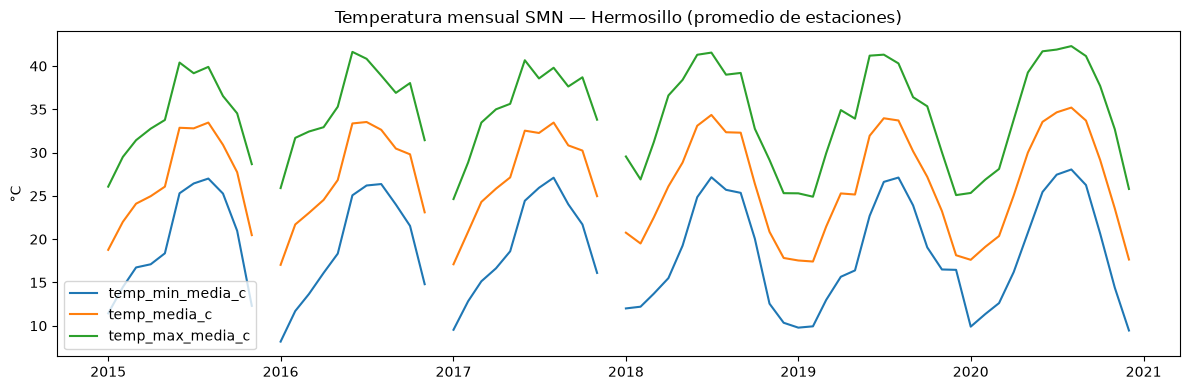

fecha_mes
2018-01    2
2018-02    2
2018-03    2
2018-04    1
2018-05    2
2018-06    2
2018-07    2
2018-08    2
2018-09    2
2018-10    2
2018-11    2
2018-12    2
2019-01    2
2019-02    2
2019-03    2
2019-04    1
2019-05    2
2019-06    2
2019-07    2
2019-08    2
2019-09    2
2019-10    2
2019-11    2
2019-12    2
2020-01    2
2020-02    2
2020-03    2
2020-04    2
2020-05    2
2020-06    2
2020-07    2
2020-08    2
2020-09    2
2020-10    2
2020-11    2
2020-12    2
Freq: M, dtype: int64

In [16]:
# Crea la figura (fig) y su área de dibujo (ax). figsize = ancho y alto en pulgadas.
fig, ax = plt.subplots(figsize=(12, 4))
# Dibuja una línea por cada columna de temperatura: eje X = mes, eje Y = temperatura.
for col in ["temp_min_media_c", "temp_media_c", "temp_max_media_c"]:
    ax.plot(temp_mensual["fecha_mes"], temp_mensual[col], label=col)
ax.set_ylabel("°C")  # etiqueta del eje vertical
ax.set_title("Temperatura mensual SMN — Hermosillo (promedio de estaciones)")  # título
ax.legend()  # muestra la leyenda con el nombre de cada línea
plt.tight_layout()  # ajusta los márgenes para que no se corte nada
plt.show()  # muestra la gráfica

# Meses en los que se promedió con menos de 3 estaciones
n_estaciones[n_estaciones < 3]

## Guardar salida

**Qué se hace:** se guarda la serie de Hermosillo en un archivo CSV, `data/interim/clima/temperatura_smn_hermosillo_mensual.csv`.

**Para qué sirve:** dejar una copia para revisarla fuera del notebook (por ejemplo en Excel). El panel **no** lee este archivo: llama directo a `climate_hermosillo()`.

**Cómo activarlo:** la celda de abajo está comentada a propósito, para guardar solo cuando la serie esté validada. Para activarlo, quita el `#` del inicio de las dos últimas líneas y ejecuta la celda.

In [15]:
# Crea la carpeta data/interim/clima si no existe (parents=True crea también las carpetas intermedias)
OUT_DIR.mkdir(parents=True, exist_ok=True)
# Guarda la serie en CSV; index=False evita guardar el número de fila como columna extra
temp_mensual.to_csv(OUT_DIR / "temperatura_smn_hermosillo_mensual.csv", index=False)

## Decisiones de procesamiento

Registrar cada decisión que cambie los datos y su justificación. Si la
decisión cambia el panel, implementarla en `sonora_health_climate_eda/panel.py`
(es lo que ejecuta `03_eda/3.0-integracion-espacial.ipynb`) y llevarla al
reporte final.

| Variable / periodo | Problema | Decisión | Justificación |
|--------------------|----------|----------|---------------|
| dic-2015, dic-2016, dic-2017 (TMed/TMax/TMin) | Archivo SMN degenerado | NaN | Valor idéntico en las tres series y ~8–10 °C sobre el diciembre típico |
| Estaciones HMNSO (70 meses) y MMHO (36 meses), 2015-2020 | Cobertura incompleta: 34 meses con 2 estaciones y 2 meses con 1 | Sin cambios: se promedian las estaciones disponibles de cada mes | Ningún mes queda sin estaciones; pendiente evaluar `n_estaciones` si se detectan saltos |
| TMed/TMax/TMin, rangos físicos | 13 casos con Tmin > Tmed o Tmed > Tmax en todo el país | Sin cambios | Ninguno corresponde a estaciones de Hermosillo (tabla vacía) |
| Otros meses con TMed = TMax = TMin | Se buscó el patrón de archivo dañado en todos los meses | Sin cambios | Solo aparecen dic-2015, dic-2016 y dic-2017, ya tratados como NaN |
| TMed/TMax/TMin, sep-2020 (1 fila por serie con valor `-99.9`) | Fila con valor centinela y sin clave ni nombre de estación | Sin cambios | No corresponde a ninguna estación de Hermosillo, así que no entra al promedio de la serie |

In [20]:
# Ver como quedó el DF final
temp_mensual.head()

,fecha_mes,temp_media_c,temp_max_media_c,temp_min_media_c
0,2015-01-01,18.766667,26.066667,11.433333
1,2015-02-01,22.000000,29.500000,14.466667
2,2015-03-01,24.100000,31.433333,16.733333
3,2015-04-01,24.966667,32.766667,17.100000
4,2015-05-01,26.066667,33.766667,18.366667
